,Country,Total_Arrivals
91,Venezuela,16864
59,Myanmar (Burma),18455
0,Afghanistan,28075
79,Syria,29398
22,DR Congo,49828


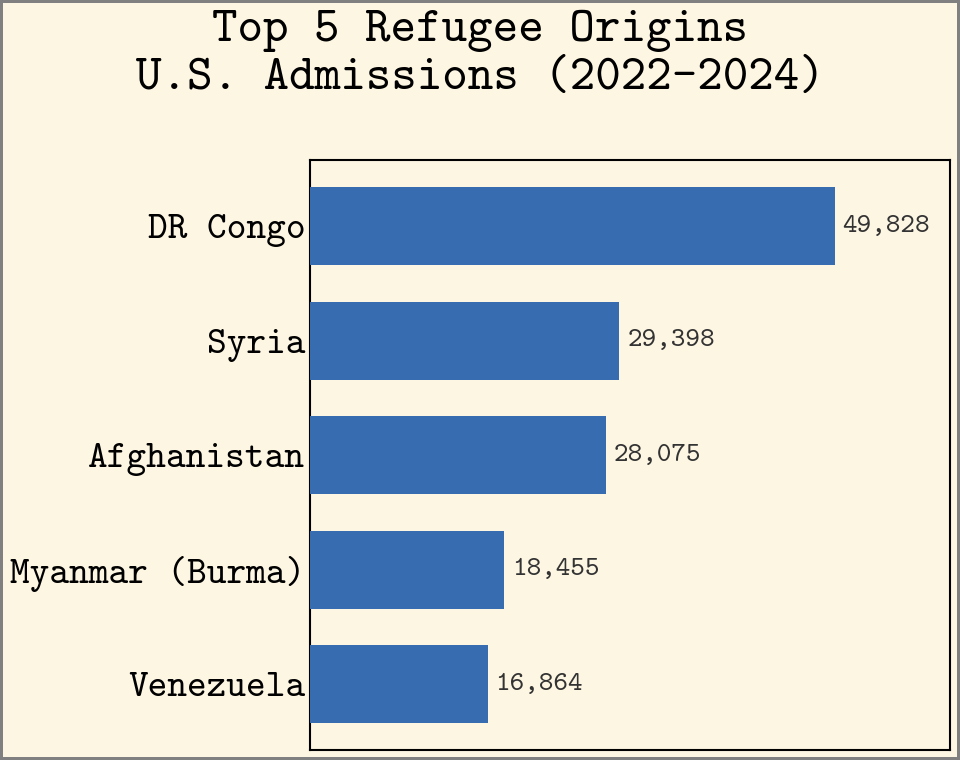

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("btt_style")

file = "ref_adm_report_2026.xlsx"

months = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# --------------------------------------------------
# 1. Read the sheets needed for calendar years 2022-2024
# FY 2025 supplies October-December 2024.
# --------------------------------------------------

all_records = []

for fy in range(2022, 2026):

    df = pd.read_excel(
        file,
        sheet_name=str(fy),
        header=None,
        usecols="A:P"
    )

    # B = Country of chargeability
    # D = Fiscal-year total
    # E:P = Monthly arrivals (October-September)

    for _, row in df.iterrows():

        country = row.iloc[1]

        if not isinstance(country, str):
            continue

        country = country.strip()

        if (
            country.startswith("Total ")
            or country == "Grand Totals"
        ):
            continue

        fy_total = pd.to_numeric(
            row.iloc[3],
            errors="coerce"
        )

        if pd.isna(fy_total):
            continue

        monthly = pd.to_numeric(
            row.iloc[4:16],
            errors="raise"
        ).fillna(0)

        # Validate this country's fiscal-year total
        if monthly.sum() != fy_total:
            raise ValueError(
                f"FY {fy}, {country}: totals don't match"
            )

        for month, arrivals in zip(months, monthly):

            year = fy - 1 if month >= 10 else fy

            all_records.append({
                "Date": pd.Timestamp(year, month, 1),
                "Country": country,
                "Arrivals": int(arrivals)
            })

# --------------------------------------------------
# 2. Combine fiscal-year sheets into calendar months
# --------------------------------------------------

df_monthly = pd.DataFrame(all_records)

name_map = {
    "Dem. Rep. Congo": "DR Congo",
    "Burma": "Myanmar (Burma)"
}

df_monthly["Country"] = (
    df_monthly["Country"].replace(name_map)
)

# --------------------------------------------------
# 3. Filter to complete calendar years 2022-2024
# --------------------------------------------------

df_biden = df_monthly[
    df_monthly["Date"].dt.year.between(2022, 2024)
].copy()

# --------------------------------------------------
# 4. Calculate total refugee arrivals for top 5
# --------------------------------------------------

df_top5 = (
    df_biden
    .groupby("Country", as_index=False)["Arrivals"]
    .sum()
    .rename(columns={"Arrivals": "Total_Arrivals"})
    .nlargest(5, "Total_Arrivals")
    .sort_values("Total_Arrivals")
)

display(df_top5)

# --------------------------------------------------
# 5. Build BTT horizontal bar chart
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 8),
    layout="constrained"
)

bar_color = "#386CB0"

bars = ax.barh(
    df_top5["Country"],
    df_top5["Total_Arrivals"],
    color=bar_color,
    edgecolor="none",
    height=0.68,
    zorder=3
)

max_val = df_top5["Total_Arrivals"].max()

# --------------------------------------------------
# 6. Numerical labels
# --------------------------------------------------

for bar in bars:

    width = bar.get_width()

    ax.text(
        width + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        ha="left",
        fontsize=20,
        color="#333333"
    )

# --------------------------------------------------
# 7. Figure title
# --------------------------------------------------

fig.suptitle(
    "Top 5 Refugee Origins\n"
    "U.S. Admissions (2022-2024)",
    fontsize=35,
    fontweight="bold"
)

# --------------------------------------------------
# 8. Axis formatting
# --------------------------------------------------

ax.set_xlim(0, max_val * 1.22)

# Large country labels for mobile
ax.tick_params(
    axis="y",
    labelsize=27,
    length=0
)

# Hide x-axis title, ticks, and labels
ax.set_xlabel("")

ax.tick_params(
    axis="x",
    bottom=False,
    top=False,
    labelbottom=False
)

ax.grid(False)

# Keep BTT chart borders
for spine in ax.spines.values():
    spine.set_visible(True)

# --------------------------------------------------
# 9. Save figure
# --------------------------------------------------

fig.patch.set_linewidth(4)

fig.savefig(
    "biden_top5_refugees_total.png",
    dpi=600
)

plt.show()

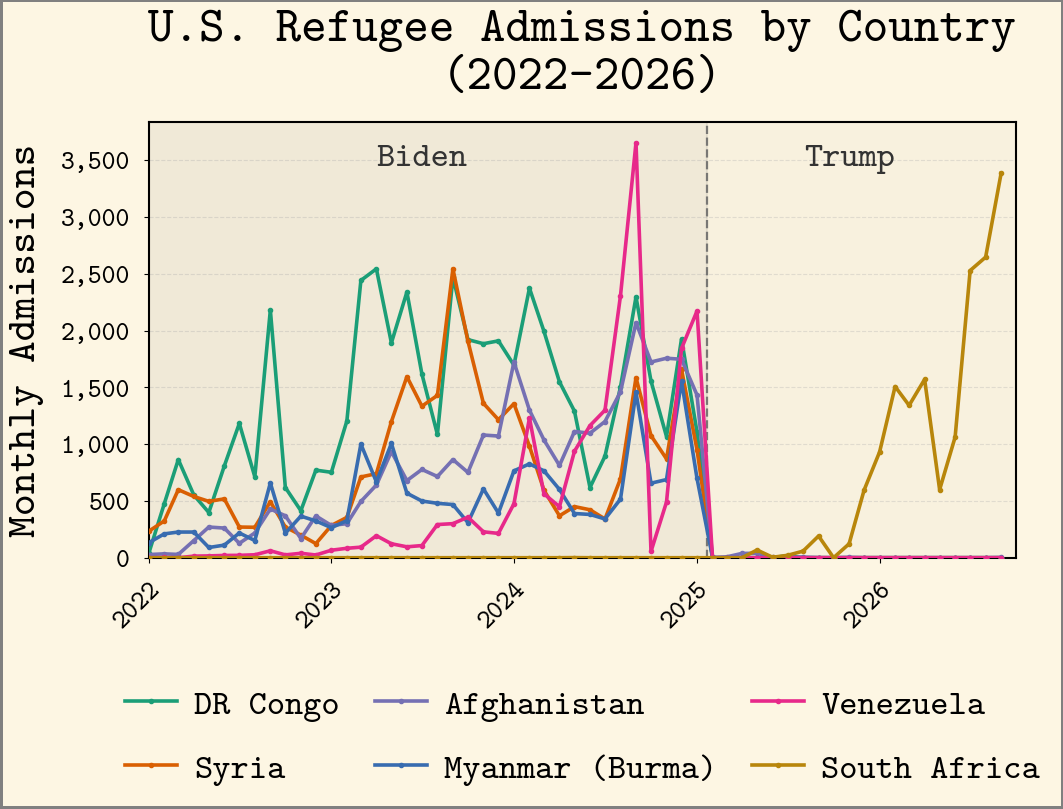

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# 1. Apply custom BTT style
# --------------------------------------------------

plt.style.use("btt_style")

file = "ref_adm_report_2026.xlsx"

months = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# --------------------------------------------------
# 2. Extract monthly admissions for FY 2022-2026
# --------------------------------------------------

all_records = []

for fy in range(2022, 2027):

    df = pd.read_excel(
        file,
        sheet_name=str(fy),
        header=None,
        usecols="A:P"
    )

    for _, row in df.iterrows():

        country = row.iloc[1]

        if not isinstance(country, str):
            continue

        country = country.strip()

        # Exclude regional and national totals
        if (
            country.startswith("Total ")
            or country == "Grand Totals"
        ):
            continue

        fy_total = pd.to_numeric(
            row.iloc[3],
            errors="coerce"
        )

        if pd.isna(fy_total):
            continue

        monthly = pd.to_numeric(
            row.iloc[4:16],
            errors="raise"
        ).fillna(0)

        # Verify fiscal-year total
        if monthly.sum() != fy_total:
            raise ValueError(
                f"FY {fy}, {country}: totals don't match"
            )

        for month, arrivals in zip(months, monthly):

            year = fy - 1 if month >= 10 else fy

            all_records.append({
                "Date": pd.Timestamp(year, month, 1),
                "Country": country,
                "Arrivals": int(arrivals)
            })

# --------------------------------------------------
# 3. Combine into a monthly dataframe
# --------------------------------------------------

df_monthly = pd.DataFrame(all_records)

name_map = {
    "Dem. Rep. Congo": "DR Congo",
    "Burma": "Myanmar (Burma)"
}

df_monthly["Country"] = (
    df_monthly["Country"].replace(name_map)
)

# Keep January 2022 through September 2026
start_date = pd.Timestamp("2022-01-01")
end_date = pd.Timestamp("2026-09-01")

df_monthly = df_monthly[
    df_monthly["Date"].between(start_date, end_date)
].copy()

# --------------------------------------------------
# 4. Select the five countries plus South Africa
# --------------------------------------------------

display_order = [
    "DR Congo",
    "Syria",
    "Afghanistan",
    "Myanmar (Burma)",
    "Venezuela",
    "South Africa"
]

# Ensure all six countries are present
missing_countries = (
    set(display_order) - set(df_monthly["Country"])
)

if missing_countries:
    raise ValueError(
        f"Missing countries: {missing_countries}"
    )

# Aggregate across country and month
df_grouped = (
    df_monthly[
        df_monthly["Country"].isin(display_order)
    ]
    .groupby(["Date", "Country"], as_index=False)["Arrivals"]
    .sum()
)

# Include months with zero arrivals
all_dates = pd.date_range(
    start_date,
    end_date,
    freq="MS"
)

full_index = pd.MultiIndex.from_product(
    [all_dates, display_order],
    names=["Date", "Country"]
)

df_grouped = (
    df_grouped
    .set_index(["Date", "Country"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

# --------------------------------------------------
# 5. Build visualization
# --------------------------------------------------

# Disable automatic layout so manual margins work
fig, ax = plt.subplots(
    figsize=(11, 8.5),
    layout="none"
)

# Presidency shading
transition = pd.Timestamp("2025-01-20")
plot_end = pd.Timestamp("2026-10-01")

ax.axvspan(
    start_date,
    transition,
    color="#000000",
    alpha=0.05,
    zorder=1
)

ax.axvspan(
    transition,
    plot_end,
    color="#000000",
    alpha=0.02,
    zorder=1
)

# --------------------------------------------------
# 6. Country colors
# --------------------------------------------------

palette = {
    "DR Congo": "#1B9E77",
    "Syria": "#D95F02",
    "Afghanistan": "#7570B3",
    "Myanmar (Burma)": "#386CB0",
    "Venezuela": "#E7298A",
    "South Africa": "#B8860B"
}

# Plot monthly arrivals
for country in display_order:

    group = df_grouped[
        df_grouped["Country"] == country
    ].sort_values("Date")

    ax.plot(
        group["Date"],
        group["Arrivals"],
        marker="o",
        markersize=3,
        linewidth=2.6,
        label=country,
        color=palette[country],
        zorder=3
    )

# --------------------------------------------------
# 7. Presidential transition marker
# --------------------------------------------------

ax.axvline(
    transition,
    color="#666666",
    linestyle="--",
    linewidth=1.6,
    alpha=0.85,
    zorder=2
)

# --------------------------------------------------
# 8. Titles, labels, and limits
# --------------------------------------------------

ax.set_title(
    "U.S. Refugee Admissions by Country\n"
    "(2022-2026)",
    pad=24,
    fontsize=35,
    fontweight="bold"
)

ax.set_ylabel(
    "Monthly Admissions",
    fontsize=30,
    labelpad=12
)

# Remove x-axis title
ax.set_xlabel("")

ax.set_xlim(start_date, plot_end)
ax.set_ylim(bottom=0)

# --------------------------------------------------
# 9. X-axis: calendar years rotated 45 degrees
# --------------------------------------------------

ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.tick_params(
    axis="x",
    labelsize=19,
    labelrotation=45,
    pad=10
)

# Align rotated labels properly
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_rotation_mode("anchor")

# Y-axis formatting
ax.yaxis.set_major_formatter("{x:,.0f}")

ax.tick_params(
    axis="y",
    labelsize=19,
    pad=10
)

# --------------------------------------------------
# 10. Presidency labels
# --------------------------------------------------

ymax = ax.get_ylim()[1]

ax.text(
    pd.Timestamp("2023-07-01"),
    ymax * 0.95,
    "Biden",
    ha="center",
    va="top",
    fontsize=25,
    fontweight="bold",
    color="#333333"
)

ax.text(
    pd.Timestamp("2025-11-01"),
    ymax * 0.95,
    "Trump",
    ha="center",
    va="top",
    fontsize=25,
    fontweight="bold",
    color="#333333"
)

# --------------------------------------------------
# 11. Larger legend below chart
# --------------------------------------------------

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.27),
    ncol=3,
    fontsize=25,
    labelspacing=0.9,
    columnspacing=1.0,
    handlelength=1.5,
    handletextpad=0.5,
    borderaxespad=0
)

# --------------------------------------------------
# 12. Grid and styling
# --------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    zorder=0
)

ax.set_axisbelow(True)

# Keep BTT chart borders
for spine in ax.spines.values():
    spine.set_visible(True)

# --------------------------------------------------
# 13. Layout
# --------------------------------------------------

fig.subplots_adjust(
    left=0.15,
    right=0.96,
    top=0.82,
    bottom=0.31
)

fig.patch.set_linewidth(4)

# --------------------------------------------------
# 14. Save figure
# --------------------------------------------------

fig.savefig(
    "refugee_timeseries_2022_2026.png",
    dpi=600
)

plt.show()